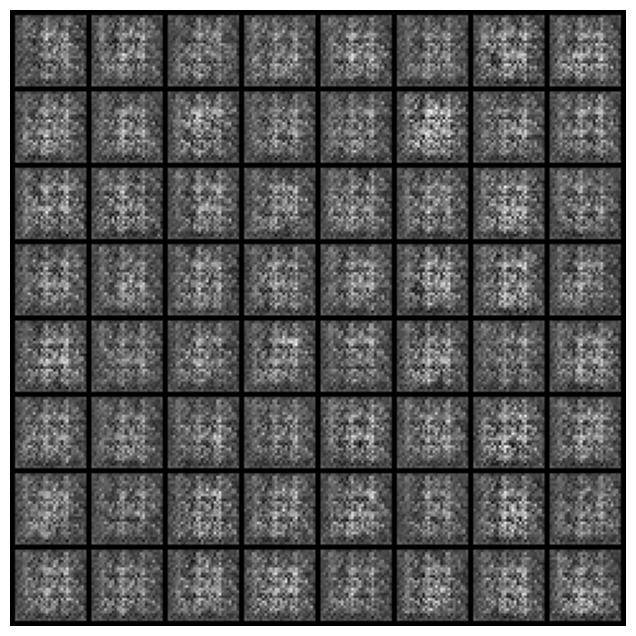

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.utils.prune as prune
import torch.nn.functional as F
import torch.quantization
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset_full = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
dataset = torch.utils.data.Subset(dataset_full, range(2000))
dataloader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True)

class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=1):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 3, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 3, 2, 0, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        return self.main(input)

class Discriminator(nn.Module):
    def __init__(self, nc=1, ndf=64):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 3, 2, 0, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, 1, 3, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input)

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG = Generator().to(device)
netG.apply(weights_init)

netD = Discriminator().to(device)
netD.apply(weights_init)

criterion = nn.BCELoss()
fixed_noise = torch.randn(64, 100, 1, 1, device=device)

optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

def train_gan(epochs=3):
    img_list = []
    for epoch in range(epochs):
        for i, data in enumerate(dataloader, 0):
            netD.zero_grad()
            real_cpu = data[0].to(device)
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), 1., dtype=torch.float, device=device)
            output = netD(real_cpu).view(-1)
            errD_real = criterion(output, label)
            errD_real.backward()

            noise = torch.randn(b_size, 100, 1, 1, device=device)
            fake = netG(noise)
            label.fill_(0.)
            output = netD(fake.detach()).view(-1)
            errD_fake = criterion(output, label)
            errD_fake.backward()
            optimizerD.step()

            netG.zero_grad()
            label.fill_(1.)
            output = netD(fake).view(-1)
            errG = criterion(output, label)
            errG.backward()
            optimizerG.step()

        with torch.no_grad():
            fake = netG(fixed_noise).detach().cpu()
            img_list.append(fake)
    return img_list

def plot_generated_images(img_list):
    fig = plt.figure(figsize=(8, 8))
    plt.axis("off")
    ims = [[plt.imshow(np.transpose(torchvision.utils.make_grid(i, padding=2, normalize=True), (1,2,0)), animated=True)] for i in img_list]
    plt.show()

class TeacherNet(nn.Module):
    def __init__(self):
        super(TeacherNet, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
    def forward(self, x):
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

class StudentNet(nn.Module):
    def __init__(self):
        super(StudentNet, self).__init__()
        self.fc1 = nn.Linear(784, 64)
        self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def apply_pruning(model):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            prune.l1_unstructured(module, name='weight', amount=0.3)
            prune.remove(module, 'weight')
    return model

def apply_quantization(model):
    model.eval()
    quantized_model = torch.quantization.quantize_dynamic(
        model, {nn.Linear}, dtype=torch.qint8
    )
    return quantized_model

def distillation_loss(student_logits, teacher_logits, labels, T=2.0, alpha=0.5):
    soft_targets = F.softmax(teacher_logits / T, dim=-1)
    student_log_softmax = F.log_softmax(student_logits / T, dim=-1)

    dist_loss = F.kl_div(student_log_softmax, soft_targets, reduction='batchmean') * (T * T)
    student_loss = F.cross_entropy(student_logits, labels)

    return alpha * student_loss + (1 - alpha) * dist_loss

if __name__ == "__main__":
    generated_imgs = train_gan(epochs=3)
    plot_generated_images(generated_imgs)